saved the figure
saved the animation


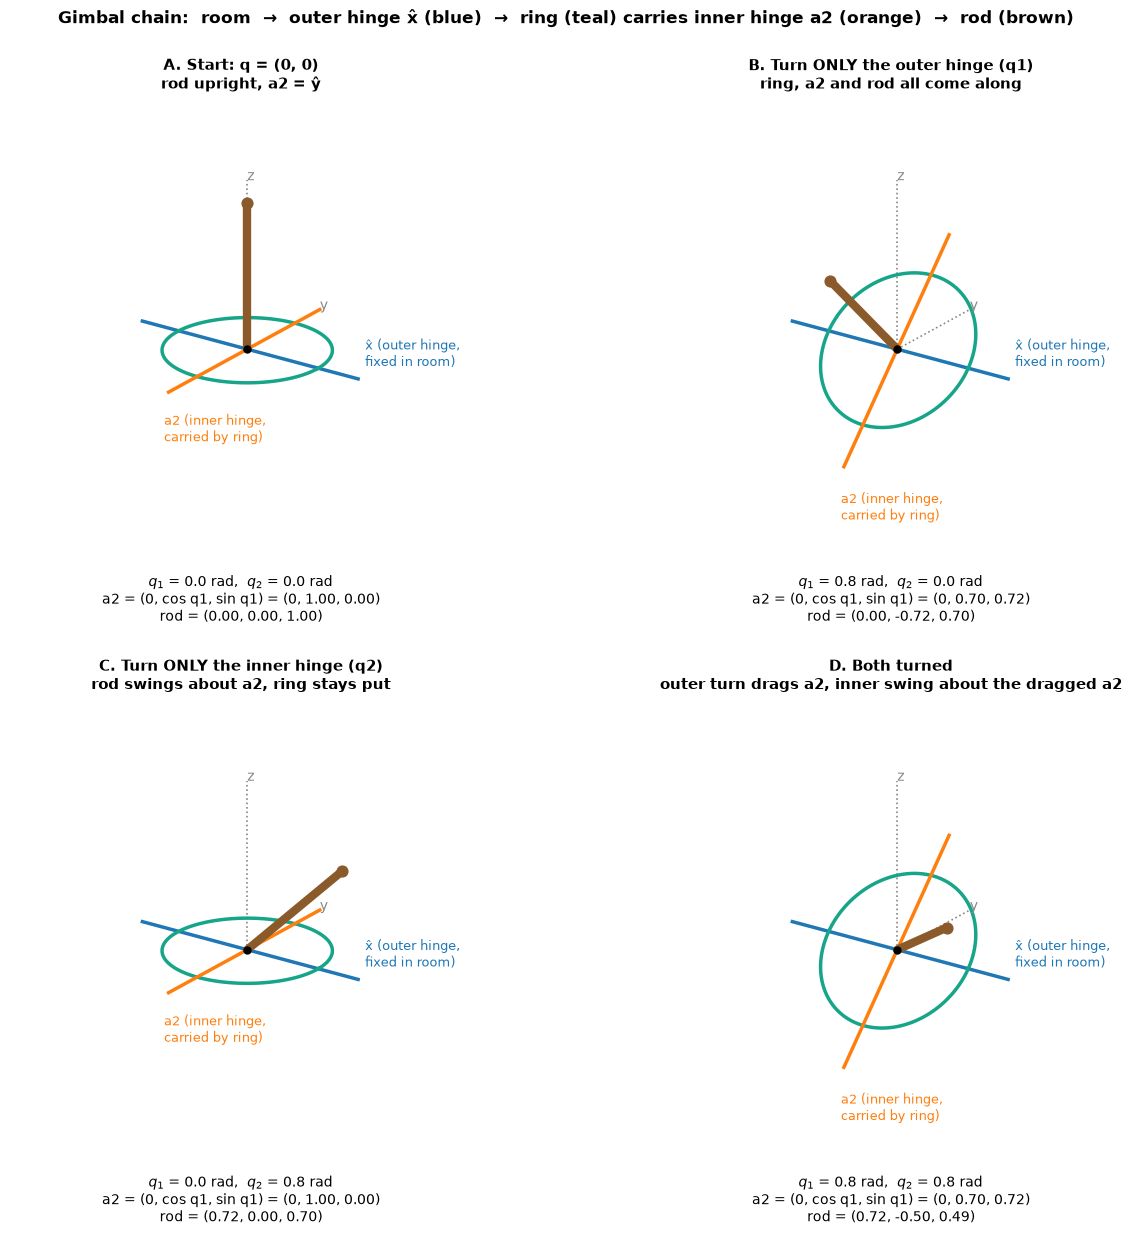

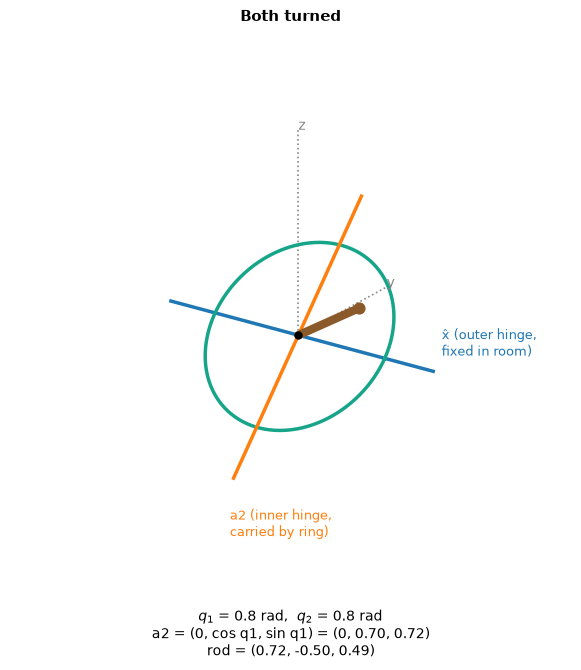

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.animation import FuncAnimation, PillowWriter  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------------------
# STEP 1: geometry of the two-hinge gimbal
# What we have: outer hinge along the lab x axis (fixed in the room), angle q1;
#               inner hinge a2 carried by the outer ring, angle q2 relative to the ring;
#               rod fixed to the inner hinge, upright at q = 0.
# What we want: the positions of the hinge axes, the ring and the rod for any (q1, q2).
# Why: to SEE that turning q1 drags a2 and the rod along, while turning q2 only swings
#      the rod about a2.
# Formulas:
#   x_hat = (1, 0, 0)
#   a2    = (0, cos q1, sin q1)
#   rod   = (sin q2, -sin q1 cos q2, cos q1 cos q2)
# ---------------------------------------------------------------------------
X_HAT = np.array([1.0, 0.0, 0.0])
BLUE, ORANGE, TEAL, BROWN, GRAY = "#1f77b4", "#ff7f0e", "#17a589", "#8b5a2b", "#888888"
RING_R = 0.55
ROD_L = 1.0


def a2_of(q1):
    return np.array([0.0, np.cos(q1), np.sin(q1)])


def rod_of(q1, q2):
    return np.array([np.sin(q2), -np.sin(q1) * np.cos(q2), np.cos(q1) * np.cos(q2)])


# ---------------------------------------------------------------------------
# STEP 2: draw one pose
# What we have: (q1, q2) and a 3D axes.
# What we want: gray room axes, blue outer hinge, teal ring, orange inner hinge, brown rod.
# Why: colors tell you which piece is fixed in the room (blue) and which pieces move.
# ---------------------------------------------------------------------------
def draw_pose(ax, q1, q2, title, note=True):
    a2 = a2_of(q1)
    u = rod_of(q1, q2)
    t = np.linspace(0, 2 * np.pi, 120)
    ring = RING_R * (np.cos(t)[:, None] * X_HAT + np.sin(t)[:, None] * a2)

    # room axes y and z (gray, dotted)
    for vec, lab in ((np.array([0, 0.85, 0]), "y"), (np.array([0, 0, 1.15]), "z")):
        ax.plot([0, vec[0]], [0, vec[1]], [0, vec[2]], ":", color=GRAY, lw=1.2)
        ax.text(vec[0], vec[1], vec[2], lab, color=GRAY, fontsize=10)

    # outer hinge (fixed in the room)
    ax.plot([-0.85, 0.85], [0, 0], [0, 0], color=BLUE, lw=2.5)
    ax.text(0.9, 0, 0.1, "x̂ (outer hinge,\nfixed in room)", color=BLUE, fontsize=9)

    # ring (carried by the outer hinge)
    ax.plot(ring[:, 0], ring[:, 1], ring[:, 2], color=TEAL, lw=2.5)

    # inner hinge a2 (carried by the ring)
    ax.plot([-0.85 * a2[0], 0.85 * a2[0]], [-0.85 * a2[1], 0.85 * a2[1]],
            [-0.85 * a2[2], 0.85 * a2[2]], color=ORANGE, lw=2.5)
    ax.text(-0.9 * a2[0], -0.9 * a2[1], -0.9 * a2[2] - 0.12, "a2 (inner hinge,\ncarried by ring)",
            color=ORANGE, fontsize=9, va="top")

    # rod
    tip = ROD_L * u
    ax.plot([0, tip[0]], [0, tip[1]], [0, tip[2]], color=BROWN, lw=6, solid_capstyle="round")
    ax.scatter([tip[0]], [tip[1]], [tip[2]], color=BROWN, s=60)
    ax.scatter([0], [0], [0], color="k", s=25)

    ax.set_xlim(-1.0, 1.0)
    ax.set_ylim(-1.0, 1.0)
    ax.set_zlim(-0.9, 1.2)
    ax.set_box_aspect((2, 2, 2.1), zoom=1.15)
    ax.view_init(elev=22, azim=-55)
    ax.set_axis_off()
    ax.text2D(0.5, 1.02, title, transform=ax.transAxes, ha="center", va="bottom", fontsize=11,
              fontweight="bold")
    if note:
        txt = (f"$q_1$ = {q1:.1f} rad,  $q_2$ = {q2:.1f} rad\n"
               f"a2 = (0, cos q1, sin q1) = (0, {round(a2[1], 2) + 0.0:.2f}, {round(a2[2], 2) + 0.0:.2f})\n"
               f"rod = ({round(u[0], 2) + 0.0:.2f}, {round(u[1], 2) + 0.0:.2f}, {round(u[2], 2) + 0.0:.2f})")
        ax.text2D(0.5, -0.02, txt, transform=ax.transAxes, ha="center", va="top", fontsize=10)


# ---------------------------------------------------------------------------
# STEP 3: four poses in a 2x2 figure
# What we have: draw_pose.
# What we want: A start, B outer only, C inner only, D both.
# Why: comparing A to B shows q1 drags everything; A to C shows q2 swings only the rod;
#      D shows both together (what the real gimbal does).
# ---------------------------------------------------------------------------
Q = 0.8
poses = [
    (0.0, 0.0, "A. Start: q = (0, 0)\nrod upright, a2 = ŷ"),
    (Q, 0.0, "B. Turn ONLY the outer hinge (q1)\nring, a2 and rod all come along"),
    (0.0, Q, "C. Turn ONLY the inner hinge (q2)\nrod swings about a2, ring stays put"),
    (Q, Q, "D. Both turned\nouter turn drags a2, inner swing about the dragged a2"),
]

fig = plt.figure(figsize=(13, 12.5))
for i, (q1, q2, title) in enumerate(poses):
    ax = fig.add_subplot(2, 2, i + 1, projection="3d")
    draw_pose(ax, q1, q2, title)
fig.text(0.5, 0.975,
         "Gimbal chain:  room  →  outer hinge x̂ (blue)  →  ring (teal) carries inner hinge a2 (orange)  →  rod (brown)",
         ha="center", va="top", fontsize=12, fontweight="bold")
fig.subplots_adjust(left=0.0, right=1.0, top=0.9, bottom=0.05, wspace=0.0, hspace=0.3)
png_path = os.path.join(RESULT_DIR, f"gimbal_chain_poses_{TIMESTAMP}.png")
fig.savefig(png_path, dpi=150)
print("saved the figure")

# ---------------------------------------------------------------------------
# STEP 4: animation, outer turn first, then inner swing
# What we have: draw_pose.
# What we want: q1 from 0 to 0.8 (q2 = 0), pause, then q2 from 0 to 0.8 (q1 = 0.8), pause.
# Why: watch the ring and a2 move during the first half, and only the rod move in the second.
# ---------------------------------------------------------------------------
N = 30
HOLD = 8
frames = ([(Q * s / N, 0.0, "Step 1: outer hinge turns (q1 grows)") for s in range(N + 1)]
          + [(Q, 0.0, "Step 1 done")] * HOLD
          + [(Q, Q * s / N, "Step 2: inner hinge turns (q2 grows), rod swings about a2") for s in range(N + 1)]
          + [(Q, Q, "Both turned")] * HOLD)

fig2 = plt.figure(figsize=(8, 7.2))
ax2 = fig2.add_subplot(111, projection="3d")
fig2.subplots_adjust(left=0.0, right=1.0, top=0.9, bottom=0.12)


def update(k):
    ax2.cla()
    q1, q2, title = frames[k]
    draw_pose(ax2, q1, q2, title)


anim = FuncAnimation(fig2, update, frames=len(frames), interval=50)
gif_path = os.path.join(RESULT_DIR, f"gimbal_chain_animation_{TIMESTAMP}.gif")
anim.save(gif_path, writer=PillowWriter(fps=20), dpi=80)
print("saved the animation")

plt.show()